# VisionPort – Sign Language Recognition
## Skill 2: FastAPI, Triton, TensorRT, Model and GPU

This notebook builds an ASL alphabet image classifier and prepares it for deployment.

**Dataset limitation:** Sign Language MNIST contains 24 static alphabet classes. It excludes J and Z because those signs require motion. This project recognizes individual static hand-sign images; it does not translate continuous sign-language sentences.

**Deployment note:** Model training and ONNX export can be done in Colab. NVIDIA TensorRT and Triton serving require a compatible NVIDIA GPU environment with NVIDIA Container Toolkit / Triton container. Colab generally does not provide a Docker daemon, so the Triton launch section is intended for a compatible Linux NVIDIA machine. Do not claim Triton/TensorRT execution until those sections have actually run.


## Cell 1 – Check GPU and software

In [ ]:
!nvidia-smi

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = torch.device("cuda")
else:
    print("GPU not available; training will use CPU.")
    DEVICE = torch.device("cpu")


/bin/bash: line 1: nvidia-smi: command not found
PyTorch: 2.14.1+cpu
CUDA available: False
GPU not available; training will use CPU.


## Cell 2 – Install Python packages

In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib fastapi uvicorn python-multipart nest-asyncio onnx onnxruntime tritonclient[http]


## Cell 3 – Download Sign Language MNIST dataset

In [ ]:
import os
import pandas as pd

DATA_DIR = "/content/sign_mnist"
os.makedirs(DATA_DIR, exist_ok=True)

TRAIN_URL = "https://raw.githubusercontent.com/Elsaraf1/sign-language/main/sign_mnist_train.csv"
TEST_URL  = "https://raw.githubusercontent.com/Elsaraf1/sign-language/main/sign_mnist_test.csv"

train_csv = os.path.join(DATA_DIR, "sign_mnist_train.csv")
test_csv = os.path.join(DATA_DIR, "sign_mnist_test.csv")

if not os.path.exists(train_csv):
    !wget -q -O /content/sign_mnist/sign_mnist_train.csv $TRAIN_URL
if not os.path.exists(test_csv):
    !wget -q -O /content/sign_mnist/sign_mnist_test.csv $TEST_URL

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training columns:", train_df.shape[1])
print(train_df.head())


Training rows: 27455
Testing rows: 7172
Training columns: 785
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       230       226   
4     185  ...        92       105       105       108       133       163   

   pixel781 

## Cell 4 – Prepare labels and image tensors

In [ ]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# The dataset uses numeric labels for letters A-Z, excluding J and Z.
LETTERS = [letter for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ" if letter not in ("J", "Z")]
LABEL_TO_INDEX = {label: index for index, label in enumerate(sorted(train_df["label"].unique()))}
INDEX_TO_LETTER = {index: LETTERS[index] for index in range(len(LETTERS))}

def prepare_dataframe(df):
    labels = df["label"].map(LABEL_TO_INDEX).to_numpy(dtype=np.int64)
    pixels = df.drop(columns=["label"]).to_numpy(dtype=np.float32)
    images = pixels.reshape(-1, 1, 28, 28) / 255.0
    return torch.tensor(images), torch.tensor(labels)

X_train, y_train = prepare_dataframe(train_df)
X_test, y_test = prepare_dataframe(test_df)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256, shuffle=False)

print("Classes:", len(LETTERS))
print("Class labels:", list(INDEX_TO_LETTER.values()))
print("Training tensor:", tuple(X_train.shape))
print("Testing tensor:", tuple(X_test.shape))


Classes: 24
Class labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
Training tensor: (27455, 1, 28, 28)
Testing tensor: (7172, 1, 28, 28)


## Cell 5 – Display a sample gesture

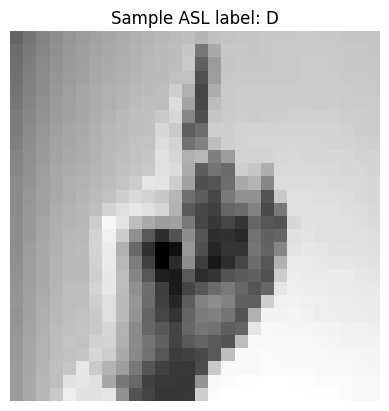

In [ ]:
import matplotlib.pyplot as plt

sample_index = 0
plt.imshow(X_train[sample_index, 0].numpy(), cmap="gray")
plt.title("Sample ASL label: " + INDEX_TO_LETTER[int(y_train[sample_index])])
plt.axis("off")
plt.show()


## Cell 6 – Build and train a CNN model

In [ ]:
import torch.nn as nn
import torch.optim as optim

class SignLanguageCNN(nn.Module):
    def __init__(self, num_classes=24):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((3, 3))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SignLanguageCNN(num_classes=len(LETTERS)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 8
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch+1}/{EPOCHS} | loss={running_loss/total:.4f} | accuracy={correct/total:.4f}")

print("Training complete.")


Epoch 1/8 | loss=2.6046 | accuracy=0.2011
Epoch 2/8 | loss=1.1562 | accuracy=0.6003
Epoch 3/8 | loss=0.6784 | accuracy=0.7565
Epoch 4/8 | loss=0.4810 | accuracy=0.8258
Epoch 5/8 | loss=0.3523 | accuracy=0.8726
Epoch 6/8 | loss=0.2730 | accuracy=0.9034
Epoch 7/8 | loss=0.2145 | accuracy=0.9229
Epoch 8/8 | loss=0.1759 | accuracy=0.9388
Training complete.


## Cell 7 – Evaluate the model

In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        predictions = outputs.argmax(1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


Test accuracy: 91.90%


## Cell 8 – Save model and export ONNX

In [ ]:
!pip install -q onnxscript
import os
import torch

ARTIFACT_DIR = "/content/visionport_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

weights_path = os.path.join(ARTIFACT_DIR, "sign_language_cnn.pth")
onnx_path = os.path.join(ARTIFACT_DIR, "model.onnx")

torch.save(model.cpu().state_dict(), weights_path)
model = model.to(DEVICE).eval()

dummy_input = torch.randn(1, 1, 28, 28)
torch.onnx.export(
    model.cpu(),
    dummy_input,
    onnx_path,
    input_names=["INPUT"],
    output_names=["OUTPUT"],
    dynamic_axes={"INPUT": {0: "batch"}, "OUTPUT": {0: "batch"}},
    opset_version=17
)
model = model.to(DEVICE)

print("Saved PyTorch weights:", weights_path)
print("Exported ONNX model:", onnx_path)


/tmp/ipykernel_741/1477908508.py:15: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1118 05:31:20.005000 741 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `SignLanguageCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SignLanguageCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved PyTorch weights: /content/visionport_artifacts/sign_language_cnn.pth
Exported ONNX model: /content/visionport_artifacts/model.onnx


## Cell 9 – Verify ONNX output

In [ ]:
import onnx
import onnxruntime as ort
import numpy as np

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

ort_session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
sample = X_test[:1].numpy().astype(np.float32)
onnx_output = ort_session.run(["OUTPUT"], {"INPUT": sample})[0]
predicted_index = int(np.argmax(onnx_output[0]))
print("ONNX test prediction:", INDEX_TO_LETTER[predicted_index])
print("ONNX output shape:", onnx_output.shape)


ONNX test prediction: G
ONNX output shape: (1, 24)


Saving 076bde8f-37a2-440c-a380-c6a969df0b89.png to 076bde8f-37a2-440c-a380-c6a969df0b89.png


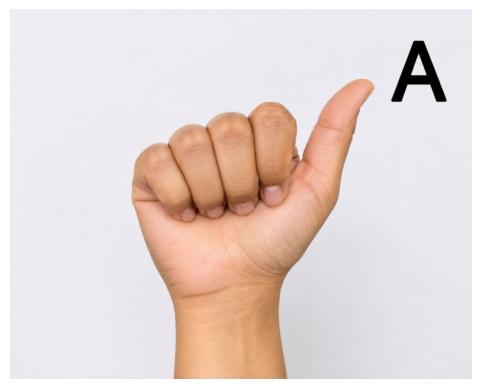

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))
img = Image.open(image_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
from google.colab import files

files.download("/content/visionport_artifacts/sign_language_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
import numpy as np
from PIL import Image

# Load and preprocess uploaded image
img = Image.open(image_path).convert("L")
img = img.resize((28, 28))

image_array = np.array(img).astype("float32") / 255.0

# Match the dataset's input format
image_tensor = torch.tensor(image_array).unsqueeze(0).unsqueeze(0)
image_tensor = image_tensor.to(DEVICE)

# Predict the alphabet
model.eval()

with torch.no_grad():
    output = model(image_tensor)
    predicted_index = output.argmax(dim=1).item()

predicted_letter = INDEX_TO_LETTER[predicted_index]

print("Predicted Sign Language Letter:", predicted_letter)

Predicted Sign Language Letter: H


## Cell 10 – Create Triton model repository (ONNX fallback)

This creates the required Triton directory structure. ONNX Runtime backend is a portable first deployment option. The TensorRT engine option is prepared in the next cell.

Triton model repository layout:
`model_repository/sign_language/1/model.onnx` plus `config.pbtxt`.


In [ ]:
import os, shutil

MODEL_REPO = "/content/model_repository"
MODEL_DIR = os.path.join(MODEL_REPO, "sign_language")
VERSION_DIR = os.path.join(MODEL_DIR, "1")
os.makedirs(VERSION_DIR, exist_ok=True)

shutil.copy2(onnx_path, os.path.join(VERSION_DIR, "model.onnx"))

config_onnx = '''
name: "sign_language"
backend: "onnxruntime"
max_batch_size: 8
input [
  {
    name: "INPUT"
    data_type: TYPE_FP32
    dims: [1, 28, 28]
  }
]
output [
  {
    name: "OUTPUT"
    data_type: TYPE_FP32
    dims: [24]
  }
]
'''

with open(os.path.join(MODEL_DIR, "config.pbtxt"), "w") as f:
    f.write(config_onnx)

print("Triton ONNX model repository created at:", MODEL_REPO)


Triton ONNX model repository created at: /content/model_repository


## Cell 11 – TensorRT engine build command (run on compatible NVIDIA Linux host)

The following command converts the ONNX model to a TensorRT plan. Run it in a TensorRT-enabled NVIDIA environment where `trtexec` is installed. A TensorRT plan is GPU-architecture / TensorRT-version sensitive; build it on the target deployment GPU.

Copy `model.onnx` to that host first.


In [ ]:
# On a compatible NVIDIA Linux machine, from the directory containing model.onnx:
# !trtexec --onnx=model.onnx --saveEngine=model.plan --fp16
#
# After successful build, put model.plan in:
# model_repository/sign_language/1/model.plan
#
# Then use this TensorRT config instead of the ONNX config:
config_trt = '''
name: "sign_language"
platform: "tensorrt_plan"
max_batch_size: 8
input [
  {
    name: "INPUT"
    data_type: TYPE_FP32
    dims: [1, 28, 28]
  }
]
output [
  {
    name: "OUTPUT"
    data_type: TYPE_FP32
    dims: [24]
  }
]
'''
print(config_trt)



name: "sign_language"
platform: "tensorrt_plan"
max_batch_size: 8
input [
  {
    name: "INPUT"
    data_type: TYPE_FP32
    dims: [1, 28, 28]
  }
]
output [
  {
    name: "OUTPUT"
    data_type: TYPE_FP32
    dims: [24]
  }
]



## Cell 12 – Triton server launch command

Run this on a compatible Linux NVIDIA host with Docker, NVIDIA Container Toolkit, and the matching Triton container available. The model repository must contain either the ONNX model/config or the TensorRT plan/config.

For TensorRT, use `config_trt` and ensure `model.plan` is present. For the portable ONNX path, use `config_onnx` and `model.onnx`.


In [ ]:
# Example commands for a Linux NVIDIA host:
# docker run --rm --gpus=all --network=host \\
#   -v $(pwd)/model_repository:/models \\
#   nvcr.io/nvidia/tritonserver:<matching-version>-py3 \\
#   tritonserver --model-repository=/models
#
# Triton defaults:
# HTTP:  localhost:8000
# gRPC:  localhost:8001
# Metrics: localhost:8002


## Cell 13 – FastAPI application that calls Triton

Run this where the Triton HTTP endpoint is reachable. If FastAPI and Triton run on the same host, the default `TRITON_URL` below is suitable. If they run on different machines, set `TRITON_URL` to the Triton host address.

The API accepts an uploaded 28x28 grayscale ASL-MNIST-style image. It returns the predicted alphabet and confidence.


In [ ]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import JSONResponse
import numpy as np
import cv2
import tritonclient.http as httpclient
import os

app = FastAPI(
    title="VisionPort Sign Language Recognition",
    description="ASL alphabet recognition using FastAPI and NVIDIA Triton",
    version="1.0"
)

TRITON_URL = os.getenv("TRITON_URL", "localhost:8000")
TRITON_MODEL = "sign_language"
LETTERS = [letter for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ" if letter not in ("J", "Z")]

def get_triton_client():
    try:
        client = httpclient.InferenceServerClient(url=TRITON_URL)
        if not client.is_server_live():
            raise RuntimeError("Triton server is not live")
        return client
    except Exception as exc:
        raise HTTPException(status_code=503, detail=f"Triton unavailable: {exc}")

@app.get("/")
def home():
    return {
        "project": "VisionPort Sign Language Recognition",
        "status": "Running",
        "model": TRITON_MODEL
    }

@app.get("/health")
def health():
    try:
        client = get_triton_client()
        ready = client.is_model_ready(TRITON_MODEL)
        return {"api": "Active", "triton": "Connected", "model_ready": ready}
    except HTTPException as exc:
        return JSONResponse(status_code=503, content={"api": "Active", "triton": "Unavailable", "detail": exc.detail})

@app.post("/predict")
async def predict_sign(file: UploadFile = File(...)):
    contents = await file.read()
    image_array = np.frombuffer(contents, dtype=np.uint8)
    image = cv2.imdecode(image_array, cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise HTTPException(status_code=400, detail="Invalid image file")

    # Match Sign Language MNIST input: grayscale 28x28, values normalized to [0,1].
    image = cv2.resize(image, (28, 28), interpolation=cv2.INTER_AREA)
    tensor = image.astype(np.float32) / 255.0
    tensor = tensor.reshape(1, 1, 28, 28)

    client = get_triton_client()
    infer_input = httpclient.InferInput("INPUT", tensor.shape, "FP32")
    infer_input.set_data_from_numpy(tensor)
    infer_output = httpclient.InferRequestedOutput("OUTPUT")

    try:
        result = client.infer(
            model_name=TRITON_MODEL,
            inputs=[infer_input],
            outputs=[infer_output]
        )
        scores = result.as_numpy("OUTPUT")[0]
    except Exception as exc:
        raise HTTPException(status_code=500, detail=f"Inference failed: {exc}")

    probabilities = np.exp(scores - np.max(scores))
    probabilities = probabilities / probabilities.sum()
    class_index = int(np.argmax(probabilities))

    return {
        "project": "VisionPort",
        "filename": file.filename,
        "predicted_sign": LETTERS[class_index],
        "confidence": round(float(probabilities[class_index]), 4),
        "status": "success"
    }

print("FastAPI application created.")


FastAPI application created.


## Cell 14 – Start FastAPI server

In [ ]:
import threading
import time
import uvicorn
import nest_asyncio
from google.colab import output
from IPython.display import display, HTML

nest_asyncio.apply()

def start_api():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="warning")

api_thread = threading.Thread(target=start_api, daemon=True)
api_thread.start()
time.sleep(2)

proxy_url = output.eval_js("google.colab.kernel.proxyPort(8000)")
display(HTML(f'<a href="{proxy_url}/docs" target="_blank">Open VisionPort API Documentation</a>'))


## Cell 15 – Test the API

Open the Swagger page, expand `POST /predict`, choose an image file, and click **Execute**.

**Important:** This API calls Triton. It will return HTTP 503 until a Triton server with the `sign_language` model is running and reachable at `TRITON_URL`. Do not expect the endpoint to work just because FastAPI starts.


In [ ]:
# Optional Python-side check from the notebook:
# import requests
# with open("/content/sample_hand.jpg", "rb") as image_file:
#     response = requests.post(proxy_url + "/predict", files={"file": image_file})
# print(response.status_code)
# print(response.json())


## Expected output format

```json
{
  "project": "VisionPort",
  "filename": "asl_sample.png",
  "predicted_sign": "A",
  "confidence": 0.96,
  "status": "success"
}
```

This is an example schema, not a measured prediction.

## Important limitations
- The Sign Language MNIST dataset contains 24 classes, excluding J and Z.
- The dataset uses small grayscale 28x28 hand crops. Arbitrary phone/webcam photos may not work well without a matching hand-cropping and preprocessing pipeline.
- This is static alphabet recognition, not full sign-language translation.
- ONNX/Triton is the portable serving path. TensorRT is the optimized NVIDIA path.
- TensorRT engine generation and Triton TensorRT serving must be executed on a compatible NVIDIA environment.
